<a href="https://colab.research.google.com/github/dolanpramanik711-droid/AIML_LAB/blob/main/Stroke_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Index (For Lab Exercise): Solve the Class Imbalance problem in the processed Stroke Dataset using the SMOTE technique, then apply different ML classifiers to the balanced dataset and show the comparative results.

Problem Statement:

You are provided with the processed Stroke Dataset. Your first task is to address the class imbalance problem present in the Dataset (processed Dataset) by applying the SMOTE (Synthetic Minority Over-Sampling Technique) to generate a balanced dataset. Then, implement all five Machine Learning classifiers and the Artificial Neural Network (ANN), for a total of six classification models, as in the earlier laboratory exercise. Evaluate the performance of each classifier using the following metrics: Precision, Recall, F1-Score, Accuracy, and AUC-ROC. Generate and display the Confusion Matrix for each model based on the balanced dataset.
Next, compare the performance of all six classifiers on the SMOTE-balanced dataset with their corresponding results obtained from the original imbalanced dataset. Based on the comparative evaluation, identify the top three performing models in predicting stroke risk using the balanced dataset. Present the final comparative results in a clear and structured tabular format.

In [ ]:

!pip install imbalanced-learn


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)


In [ ]:

# Load the processed Stroke Dataset

df = pd.read_csv('/content/stroke_processed_5k.csv')

# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Display number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Count Stroke and No Stroke cases
print("\nStroke Class Distribution:")
print(df['stroke'].value_counts())


First 5 Rows:
   gender       age  hypertension  heart_disease  ever_married  work_type  \
0       1  1.051434             0              1             1          2   
1       0  0.786070             0              0             1          3   
2       1  1.626390             0              1             1          2   
3       0  0.255342             0              0             1          2   
4       0  1.582163             1              0             1          3   

   Residence_type  avg_glucose_level       bmi  smoking_status  stroke  
0               1           2.706375  1.005086               1       1  
1               0           2.121559 -0.098981               2       1  
2               0          -0.005028  0.472536               2       1  
3               1           1.437358  0.719327               3       1  
4               0           1.501184 -0.631531               2       1  

Dataset Shape:
(5110, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'

In [ ]:

X = df.drop('stroke', axis=1)
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())


Before SMOTE:
stroke
0    3889
1     199
Name: count, dtype: int64

After SMOTE:
stroke
0    3889
1    3889
Name: count, dtype: int64


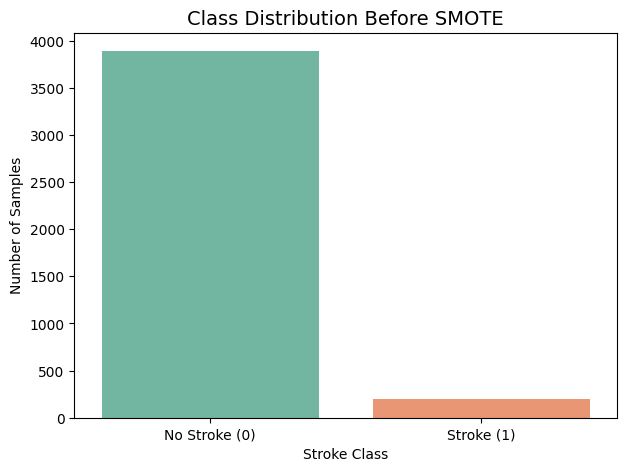

In [ ]:

# Class distribution before SMOTE

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train, hue=y_train,
              palette='Set2', legend=False)

plt.title('Class Distribution Before SMOTE',
          fontsize=14)
plt.xlabel('Stroke Class')
plt.ylabel('Number of Samples')
plt.xticks([0, 1], ['No Stroke (0)', 'Stroke (1)'])

plt.show()


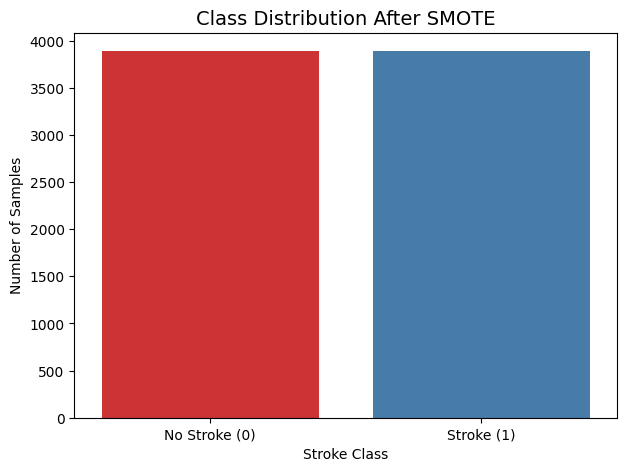

In [ ]:

# Class distribution after SMOTE

plt.figure(figsize=(7, 5))

sns.countplot(x=y_train_smote, hue=y_train_smote,
              palette='Set1', legend=False)

plt.title('Class Distribution After SMOTE',
          fontsize=14)
plt.xlabel('Stroke Class')
plt.ylabel('Number of Samples')
plt.xticks([0, 1], ['No Stroke (0)', 'Stroke (1)'])

plt.show()


In [ ]:

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=42),
    "ANN": MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=500,
        random_state=42
    )
}


In [ ]:

results = []

for name, model in models.items():

    model.fit(X_train_smote, y_train_smote)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Accuracy': accuracy,
        'AUC-ROC': auc
    })

    print("\nModel:", name)
    print(confusion_matrix(y_test, y_pred))



Model: Logistic Regression
[[737 235]
 [ 11  39]]

Model: Decision Tree
[[868 104]
 [ 39  11]]

Model: Random Forest
[[895  77]
 [ 38  12]]

Model: KNN
[[783 189]
 [ 31  19]]

Model: SVM
[[736 236]
 [ 16  34]]

Model: ANN
[[819 153]
 [ 30  20]]


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))


              Model  Precision  Recall  F1-Score  Accuracy  AUC-ROC
Logistic Regression   0.142336    0.78  0.240741  0.759295 0.822078
      Decision Tree   0.095652    0.22  0.133333  0.860078 0.556502
      Random Forest   0.134831    0.24  0.172662  0.887476 0.775309
                KNN   0.091346    0.38  0.147287  0.784736 0.677932
                SVM   0.125926    0.68  0.212500  0.753425 0.783745
                ANN   0.115607    0.40  0.179372  0.820939 0.736584


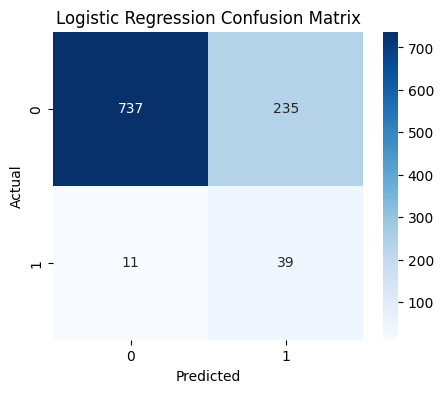

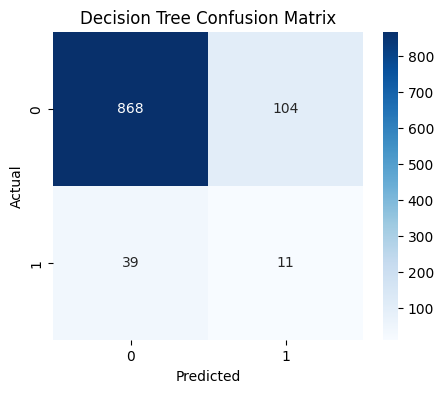

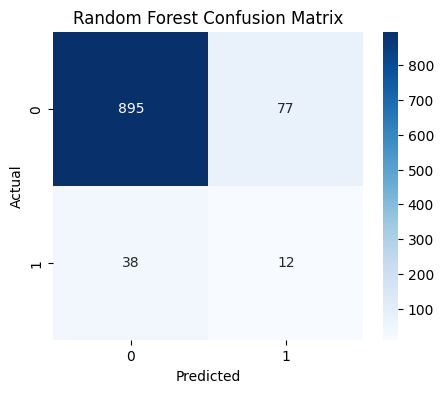

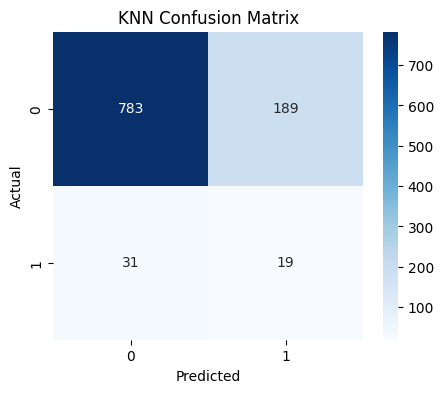

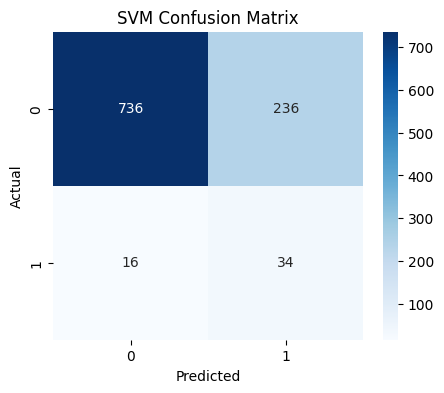

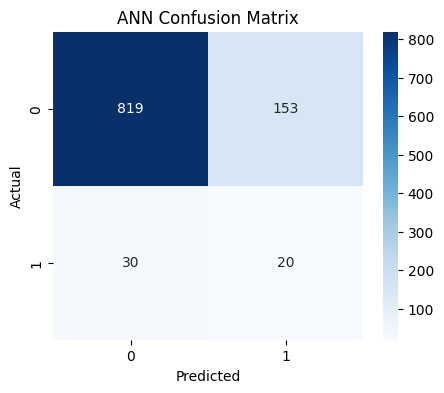

In [ ]:

for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(name + ' Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


In [ ]:

top_three = results_df.sort_values(
    by='F1-Score',
    ascending=False
).head(3)

print("Top 3 Performing Models:")
print(top_three.to_string(index=False))


Top 3 Performing Models:
              Model  Precision  Recall  F1-Score  Accuracy  AUC-ROC
Logistic Regression   0.142336    0.78  0.240741  0.759295 0.822078
                SVM   0.125926    0.68  0.212500  0.753425 0.783745
                ANN   0.115607    0.40  0.179372  0.820939 0.736584


In [15]:
import pandas as pd
from google.colab import files

# Sort results by F1-Score
results_df = results_df.sort_values(
    by='F1-Score', ascending=False
)

# Get Top 3 Models
top_three = results_df.head(3)

# Create Excel file
file_name = 'Stroke_Classification_Results.xlsx'

with pd.ExcelWriter(file_name, engine='openpyxl') as writer:

    results_df.to_excel(
        writer,
        sheet_name='Comparative Results',
        index=False
    )

    top_three.to_excel(
        writer,
        sheet_name='Top 3 Models',
        index=False
    )

# Download Excel file
files.download(file_name)

print("Excel file saved successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Excel file saved successfully!
